<a href="https://colab.research.google.com/github/Asif-Ahmed-Rezvi/flyrank-internship-ml/blob/main/work/notebooks/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Asif-Ahmed-Rezvi/flyrank-internship-ml/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.


## 1. Ranked actions + reason codes

### Objective

Create a ranked review queue that helps an SEO or content editor decide which pages to investigate first. The queue provides decision support; it does not automatically determine that a page must be refreshed.

### Ranking approach

I will retain the transparent Week-4 rule-based baseline as the primary operational reference. It prioritizes pages with at least 500 impressions over the observed 90-day window, an average search position between 1 and 20, and a CTR below 0.5%.

The score increases with search visibility and the gap between observed CTR and the 0.5% reference threshold. The CTR threshold is a screening rule, not a universal benchmark for every query or page.

### Reason codes and actions

- `high_visibility_low_ctr`: The page has meaningful search exposure, ranks within the top 20 on average, and has CTR below 0.5%. **Suggested action:** investigate search intent, title and description relevance, and search-result features before deciding whether a refresh is appropriate.
- `not_selected`: The page does not satisfy the baseline's selection conditions. **Suggested action:** monitor or assess through another workflow if other evidence indicates a problem.

### Archetype-to-action mapping

- High visibility + low CTR: investigate the search snippet, query intent, and SERP competition.
- Declining impressions + meaningful remaining visibility: investigate ranking changes, demand shifts, seasonality, and content relevance before considering a refresh.
- Low visibility + weak engagement: check indexing, technical accessibility, query demand, and measurement coverage before investing in a rewrite.
- Mature or stale content with stable performance: protect and monitor it; age alone is not sufficient reason to refresh.
- Strong performance with high business value: protect the page and avoid unnecessary changes.
- Thin, outdated, or overlapping content: assess accuracy, completeness, and cannibalization before considering expansion, consolidation, or pruning.

The archetypes above are human-review guidelines, not independently validated predictions from the current model.

### Decay and refresh insight

The earlier analysis found that impression volume is strongly associated with observed clicks, while search position is associated with CTR. Update recency alone showed only a weak relationship with CTR in the starter-data audit.

Therefore, a page's age or time since its last update should not independently trigger a refresh. A possible decline is a reason to investigate, not proof that the content is outdated or that refreshing it will restore impressions.

### Evidence limitation

In the client-grouped model evaluation, Logistic Regression matched the baseline at Precision@20 (0.65), performed slightly worse at Precision@50 (0.54 versus 0.56), and achieved higher ROC-AUC and average precision. This does not establish that the model is the better choice for a small editorial review queue. I will retain the transparent baseline unless further validation demonstrates a meaningful improvement in the decisions that matter.


In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

from pathlib import Path
import os
import pandas as pd

# Locate or clone the repository in Google Colab
repo_root = Path("/content/flyrank-internship-ml")

if os.environ.get("COLAB_RELEASE_TAG") and not repo_root.exists():
    !git clone -q https://github.com/Asif-Ahmed-Rezvi/flyrank-internship-ml /content/flyrank-internship-ml

# Search for the dataset
if not (repo_root / "data/raw/content_refresh_anonymized.csv").exists():
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    repo_root = next(
        (
            path for path in candidates
            if (path / "data/raw/content_refresh_anonymized.csv").exists()
        ),
        None,
    )

if repo_root is None or not (
    repo_root / "data/raw/content_refresh_anonymized.csv"
).exists():
    raise FileNotFoundError(
        "Dataset not found. Check whether "
        "data/raw/content_refresh_anonymized.csv exists in the repository."
    )

data_path = repo_root / "data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(data_path)

print(f"Repository: {repo_root}")
print(f"Dataset loaded: {len(df):,} rows × {len(df.columns):,} columns")

# Check required baseline features
required_columns = [
    "impressions_90d",
    "ctr",
    "avg_position",
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert features to numeric values
impressions = pd.to_numeric(
    df["impressions_90d"], errors="coerce"
).fillna(0).clip(lower=0)

ctr = pd.to_numeric(
    df["ctr"], errors="coerce"
)

avg_position = pd.to_numeric(
    df["avg_position"], errors="coerce"
).fillna(0)

# Reproduce the transparent Week-4 baseline rule
visibility_gate = (
    impressions.ge(500)
    & avg_position.gt(0)
    & avg_position.le(20)
)

ctr_gap = (
    (0.5 - ctr).clip(lower=0) / 0.5
).fillna(0)

priority_score = (
    np.log1p(impressions)
    * ctr_gap
    * visibility_gate.astype(int)
)

# Build the human-review queue
queue = pd.DataFrame(index=df.index)

# Include an available content identifier
identifier_column = next(
    (
        column for column in ["content_id", "content_hash_id"]
        if column in df.columns
    ),
    None,
)

if identifier_column is not None:
    queue["content_id"] = df[identifier_column]

# Include useful context when available
context_columns = [
    "content_type",
    "impressions_90d",
    "clicks_90d",
    "ctr",
    "avg_position",
    "content_age_days",
    "days_since_last_update",
]

for column in context_columns:
    if column in df.columns and column not in queue.columns:
        queue[column] = df[column]

queue["priority_score"] = priority_score
queue["reason_code"] = np.where(
    priority_score.gt(0),
    "high_visibility_low_ctr",
    "not_selected",
)
queue["action"] = np.where(
    priority_score.gt(0),
    "refresh_and_review_ctr",
    "monitor",
)

# Rank highest-priority pages first
queue = queue.sort_values(
    ["priority_score"],
    ascending=False,
    kind="stable",
).reset_index(drop=True)

queue.insert(
    0,
    "priority_rank",
    np.arange(1, len(queue) + 1),
)

# Basic checks
selected_count = int(queue["priority_score"].gt(0).sum())

print(f"Repository: {repo_root}")
print(f"Input rows: {len(df):,}")
print(f"Pages selected for review: {selected_count:,}")
print(f"Pages not selected: {len(queue) - selected_count:,}")
print("\nTop 20 ranked pages:")

display(queue.head(20))

# Confirm the ranking and reason codes are consistent
assert queue["priority_score"].is_monotonic_decreasing
assert (
    queue.loc[
        queue["priority_score"].gt(0), "reason_code"
    ].eq("high_visibility_low_ctr").all()
)
assert (
    queue.loc[
        queue["priority_score"].eq(0), "reason_code"
    ].eq("not_selected").all()
)

print("\nChecks passed: ranking order and reason codes are consistent.")
print(
    "Reminder: this is a rule-based review queue, "
    "not a prediction of future performance."
)

Repository: /content/flyrank-internship-ml
Dataset loaded: 30,000 rows × 44 columns
Repository: /content/flyrank-internship-ml
Input rows: 30,000
Pages selected for review: 9,759
Pages not selected: 20,241

Top 20 ranked pages:


,priority_rank,content_id,content_type,impressions_90d,clicks_90d,ctr,avg_position,content_age_days,days_since_last_update,priority_score,reason_code,action
0,1,content_c8e9d6ab9013,keyword article,208678,0,0.00,9.7,362,104,12.248552,high_visibility_low_ctr,refresh_and_review_ctr
1,2,content_8451fc6f034d,keyword article,272144,75,0.03,2.3,280,20,11.763245,high_visibility_low_ctr,refresh_and_review_ctr
2,3,content_453722754fea,keyword article,140079,16,0.01,7.6,97,20,11.612970,high_visibility_low_ctr,refresh_and_review_ctr
3,4,content_c84a0ab98e90,keyword article,223271,70,0.03,7.8,95,20,11.577177,high_visibility_low_ctr,refresh_and_review_ctr
4,5,content_4a6607efcb46,keyword article,128068,17,0.01,2.2,148,104,11.525118,high_visibility_low_ctr,refresh_and_review_ctr
5,6,content_39881853ef0c,keyword article,112434,10,0.01,7.2,97,20,11.397528,high_visibility_low_ctr,refresh_and_review_ctr
6,7,content_36ff89c8214e,keyword article,295097,154,0.05,7.3,144,104,11.335557,high_visibility_low_ctr,refresh_and_review_ctr
7,8,content_0919dd345d80,keyword article,119217,26,0.02,7.0,326,7,11.221161,high_visibility_low_ctr,refresh_and_review_ctr
8,9,content_c1fe78bc4e37,keyword article,134055,43,0.03,7.5,153,104,11.097652,high_visibility_low_ctr,refresh_and_review_ctr
9,10,content_b115f7c74779,keyword article,123469,37,0.03,8.0,313,104,11.020328,high_visibility_low_ctr,refresh_and_review_ctr



Checks passed: ranking order and reason codes are consistent.
Reminder: this is a rule-based review queue, not a prediction of future performance.


## 2. Intended use and limits

### Intended users and purpose

The ranked queue is intended for SEO specialists, content editors, and content strategists who need to prioritize a large set of pages for human investigation. It provides a repeatable starting point for deciding which pages deserve closer review.

The current rule prioritizes pages with at least 500 impressions, an average position between 1 and 20, and CTR below 0.5%. A higher score means a page ranks higher under this rule; it does not mean the page is guaranteed to benefit from a refresh.

### Appropriate uses

- Select a manageable group of high-visibility, low-CTR pages for editorial review.
- Investigate whether titles, descriptions, search intent, or search-result competition may explain low CTR.
- Give editors a consistent reason code and supporting performance context.
- Combine the queue with business value, content quality, and technical SEO checks before deciding on an action.

### Limits and assumptions

- The score is a transparent rule-based ranking, not a calibrated probability of future decline or improvement.
- The 0.5% CTR threshold is a screening choice, not a universal benchmark across queries, industries, or search-result layouts.
- The observed 90-day metrics do not establish whether a page is declining over time.
- The rule does not account directly for conversion value, revenue, editorial effort, query intent, seasonality, or the reason a page receives low CTR.
- Missing or unusual measurements can affect ranking. In particular, an average position of zero is treated as unavailable and does not pass the visibility gate.
- The queue is based on the available anonymized starter dataset. Its ranking quality and business impact should not be assumed to transfer unchanged to every client or future period.

### Cost and value considerations

Reviewing every selected page may not be practical. Editors should begin with a limited top-ranked batch and estimate review effort, implementation effort, and potential business value before committing resources.

A high score can justify investigation, but it is not an estimate of revenue or expected uplift. Where possible, prioritize pages with meaningful business value and a feasible corrective action. Record the decision and rationale so later outcomes can inform the process.

### Decision boundary

The queue supports human prioritization only. It must not publish edits, rewrite or remove content, change metadata, or trigger a refresh automatically. Final decisions require human review and, where feasible, measurement of results after changes.

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Section 2: Intended-use checks and review-cost scenarios

import pandas as pd
import numpy as np
from IPython.display import display

# Confirm the queue from Section 1 exists
if "queue" not in globals():
    raise NameError("Run the Section 1 code cell first to create `queue`.")

total_pages = len(queue)
selected = queue["priority_score"].gt(0)
selected_pages = int(selected.sum())
monitor_pages = total_pages - selected_pages

# Summarize the current queue
queue_summary = pd.DataFrame(
    [
        {
            "measure": "Total pages",
            "value": total_pages,
            "interpretation": "Pages assessed by the baseline rule",
        },
        {
            "measure": "Selected for human review",
            "value": selected_pages,
            "interpretation": "Pages passing all baseline selection conditions",
        },
        {
            "measure": "Marked for monitoring",
            "value": monitor_pages,
            "interpretation": "Pages not selected by this baseline; not necessarily healthy",
        },
        {
            "measure": "Selected share (%)",
            "value": round(100 * selected_pages / total_pages, 2)
            if total_pages else 0,
            "interpretation": "Share of the input queue selected for review",
        },
    ]
)

print("Queue scope")
display(queue_summary)

# Illustrative workload scenarios; these are assumptions, not measured costs
review_minutes_per_page = [5, 10, 15]
review_scenarios = pd.DataFrame(
    {
        "minutes_per_page": review_minutes_per_page,
    }
)

review_scenarios["total_review_hours"] = (
    selected_pages * review_scenarios["minutes_per_page"] / 60
).round(1)

print("Illustrative workload for reviewing every selected page")
display(review_scenarios)

# Illustrative cost scenarios; users can change the assumed hourly rate
assumed_hourly_rate = 20.0  # Assumed currency units per hour; not a FlyRank cost estimate

review_scenarios["illustrative_cost"] = (
    review_scenarios["total_review_hours"] * assumed_hourly_rate
).round(2)

print(
    f"Illustrative cost scenarios using an assumed rate of "
    f"{assumed_hourly_rate:.2f} currency units/hour"
)
display(review_scenarios)

# Sanity checks
assert total_pages == selected_pages + monitor_pages
assert selected_pages >= 0
assert monitor_pages >= 0
assert queue["priority_score"].notna().all()

print(
    "\nChecks passed. Workload and cost values are planning scenarios only; "
    "they are not observed expenses or estimates of business uplift."
)

Queue scope


,measure,value,interpretation
0,Total pages,30000.00,Pages assessed by the baseline rule
1,Selected for human review,9759.00,Pages passing all baseline selection conditions
2,Marked for monitoring,20241.00,Pages not selected by this baseline; not neces...
3,Selected share (%),32.53,Share of the input queue selected for review


Illustrative workload for reviewing every selected page


,minutes_per_page,total_review_hours
0,5,813.2
1,10,1626.5
2,15,2439.8


Illustrative cost scenarios using an assumed rate of 20.00 currency units/hour


,minutes_per_page,total_review_hours,illustrative_cost
0,5,813.2,16264.0
1,10,1626.5,32530.0
2,15,2439.8,48796.0



Checks passed. Workload and cost values are planning scenarios only; they are not observed expenses or estimates of business uplift.


## 3. Human review + the no-go list

### Required human-review checklist

Before acting on a page in the queue, the editor must:

1. **Verify the evidence:** Check current impressions, clicks, CTR, average position, and available measurement coverage.
2. **Check search intent:** Review the relevant queries and search results to determine whether the page matches what users are looking for.
3. **Inspect the content:** Check accuracy, completeness, originality, freshness where relevant, and whether the page answers the intended question.
4. **Check technical factors:** Investigate indexing, canonical tags, internal links, page accessibility, and other technical issues when relevant.
5. **Assess business value:** Consider conversions, strategic importance, implementation effort, and the risk of changing a page that already performs well.
6. **Record the decision:** Choose refresh, expand, protect, consolidate, prune, or monitor only when supported by the evidence. Record the rationale and intended outcome.

### No-go list: actions that must not be automated

- Do not automatically publish rewritten content or modify titles, descriptions, or page copy.
- Do not automatically delete, prune, redirect, or consolidate pages based only on a score.
- Do not treat low CTR as proof of poor content quality or treat content age as proof that a refresh is necessary.
- Do not use product-generated flags or label-derived fields as model inputs.
- Do not claim that a recommended change will increase traffic, CTR, conversions, or revenue without appropriate evidence.
- Do not send client-facing recommendations without checking the underlying evidence and removing sensitive information.
- Do not interpret pages marked `not_selected` as healthy; the baseline only indicates that they did not meet its selection conditions.

### Accountability

The queue ranks candidates for investigation; a qualified human owns the final decision. Any material content change should have a documented reason, an identified reviewer, and a plan to measure outcomes where feasible. High-impact or irreversible actions require explicit human approval.

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Section 3: Human-review checklist and automation guardrails

import pandas as pd
from IPython.display import display

# Checklist of required checks before a page-level action
review_checklist = pd.DataFrame(
    [
        {
            "review_step": 1,
            "check": "Verify performance evidence and measurement coverage",
            "required": True,
        },
        {
            "review_step": 2,
            "check": "Review query intent and current search results",
            "required": True,
        },
        {
            "review_step": 3,
            "check": "Inspect content accuracy, completeness, and relevance",
            "required": True,
        },
        {
            "review_step": 4,
            "check": "Check technical SEO factors where relevant",
            "required": True,
        },
        {
            "review_step": 5,
            "check": "Assess business value, effort, and change risk",
            "required": True,
        },
        {
            "review_step": 6,
            "check": "Record the decision, rationale, and measurement plan",
            "required": True,
        },
    ]
)

print("Required human-review checklist")
display(review_checklist)

# Explicit no-go automation rules
no_go_rules = pd.DataFrame(
    [
        {
            "restricted_action": "Publish rewritten content automatically",
            "control": "Human approval required",
        },
        {
            "restricted_action": "Delete, redirect, or consolidate pages automatically",
            "control": "Human approval required",
        },
        {
            "restricted_action": "Trigger refresh solely from content age",
            "control": "Inspect evidence first",
        },
        {
            "restricted_action": "Treat not_selected as proof of page health",
            "control": "Interpret only as not selected by this rule",
        },
        {
            "restricted_action": "Claim guaranteed traffic or revenue uplift",
            "control": "Require appropriate outcome evidence",
        },
        {
            "restricted_action": "Expose client-sensitive information",
            "control": "Review and remove sensitive information",
        },
    ]
)

print("No-go automation rules")
display(no_go_rules)

# Guardrail checks
assert review_checklist["required"].all()
assert len(review_checklist) == 6
assert len(no_go_rules) == 6

# Confirm the queue contains recommendations, not execution approvals
assert "action" in queue.columns
assert not queue["action"].astype(str).str.contains(
    "auto_publish|auto_delete|auto_refresh",
    case=False,
    regex=True,
).any()

print(
    "\nChecks passed: required review steps and no-go rules are defined. "
    "The queue remains a decision-support artifact, not an execution system."
)

Required human-review checklist


,review_step,check,required
0,1,Verify performance evidence and measurement co...,True
1,2,Review query intent and current search results,True
2,3,"Inspect content accuracy, completeness, and re...",True
3,4,Check technical SEO factors where relevant,True
4,5,"Assess business value, effort, and change risk",True
5,6,"Record the decision, rationale, and measuremen...",True


No-go automation rules


,restricted_action,control
0,Publish rewritten content automatically,Human approval required
1,"Delete, redirect, or consolidate pages automat...",Human approval required
2,Trigger refresh solely from content age,Inspect evidence first
3,Treat not_selected as proof of page health,Interpret only as not selected by this rule
4,Claim guaranteed traffic or revenue uplift,Require appropriate outcome evidence
5,Expose client-sensitive information,Review and remove sensitive information



Checks passed: required review steps and no-go rules are defined. The queue remains a decision-support artifact, not an execution system.


## 4. Monitoring / retrain triggers

### What to monitor

The queue should be reviewed periodically to determine whether its recommendations remain useful and whether the underlying data have changed.

- **Input data quality:** Monitor missing values, unexpected ranges, changes in CTR units, and the handling of average position equal to zero.
- **Queue composition:** Track the number and percentage of pages selected, the distribution of priority scores, and changes in reason-code frequency.
- **Ranking usefulness:** Have editors assess whether high-ranked pages contain actionable opportunities. Record accepted recommendations, rejected recommendations, and the reasons for rejection.
- **Observed outcomes:** Where changes are implemented, compare relevant performance before and after the change while accounting for seasonality, demand changes, and other possible explanations. Before-and-after differences alone do not establish causation.
- **Operational effort:** Track review time, implementation effort, and the proportion of reviewed pages that lead to a justified action.

### Review and retrain triggers

Revisit the rule or model when:

1. Input schemas, metric definitions, or CTR units change.
2. Missingness or feature distributions shift materially from the development data.
3. The share of pages selected changes unexpectedly or the score distribution becomes unusual.
4. Editors repeatedly reject high-ranked recommendations or find that the queue misses important opportunities.
5. Evaluation on a suitable later time period shows weaker ranking quality or reduced usefulness.
6. The content portfolio, search environment, or business objective changes enough that the original thresholds no longer make sense.

These triggers are reasons to investigate, not automatic instructions to retrain or replace the baseline.

### Evaluation and retraining policy

The client-grouped evaluation showed that Logistic Regression improved ROC-AUC and average precision over the baseline, but did not improve Precision@20 and performed slightly worse at Precision@50. Grouped evaluation tests performance on unseen clients; it does not, by itself, establish future-calendar performance.

Keep the transparent baseline as the operational reference until a candidate demonstrates a meaningful improvement on an appropriate evaluation set, especially at the review-queue sizes editors can realistically handle. Any retraining should use documented feature definitions, leakage checks, and a suitable time-based holdout where available.

### Human oversight

Monitoring may flag a need to investigate, but it must not automatically change content or deploy a new model. A responsible reviewer should approve changes to the scoring rule, thresholds, or model and document the reason for the change.

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Section 4: Monitoring metrics and proposed investigation triggers

import pandas as pd
import numpy as np
from IPython.display import display

if "df" not in globals() or "queue" not in globals():
    raise NameError(
        "Run the Section 1 code cell first so `df` and `queue` exist."
    )

# Monitor data quality for the features used by the baseline
feature_columns = [
    "impressions_90d",
    "ctr",
    "avg_position",
]

quality_rows = []

for column in feature_columns:
    values = pd.to_numeric(df[column], errors="coerce")
    quality_rows.append(
        {
            "feature": column,
            "missing_or_non_numeric_pct": round(
                100 * values.isna().mean(), 2
            ),
            "unique_values": int(values.nunique(dropna=True)),
        }
    )

data_quality_report = pd.DataFrame(quality_rows)

print("Input data quality")
display(data_quality_report)

# Monitor selection and ranking characteristics
selected_mask = queue["priority_score"].gt(0)
selected_scores = queue.loc[selected_mask, "priority_score"]

monitoring_summary = pd.DataFrame(
    [
        {
            "metric": "Total pages scored",
            "observed_value": int(len(queue)),
            "proposed_trigger": "Investigate unexpected volume changes",
        },
        {
            "metric": "Selected share (%)",
            "observed_value": round(
                100 * selected_mask.mean(), 2
            ) if len(queue) else 0,
            "proposed_trigger": "Investigate changes of more than 10 percentage points versus a documented reference",
        },
        {
            "metric": "Median selected priority score",
            "observed_value": round(
                float(selected_scores.median()), 4
            ) if not selected_scores.empty else 0,
            "proposed_trigger": "Investigate material shifts in score distribution",
        },
        {
            "metric": "Pages with missing CTR (%)",
            "observed_value": round(
                100 * pd.to_numeric(
                    df["ctr"], errors="coerce"
                ).isna().mean(),
                2,
            ),
            "proposed_trigger": "Investigate increases in missing CTR values",
        },
    ]
)

print("Monitoring summary")
display(monitoring_summary)

# Document proposed triggers for human investigation
monitoring_triggers = pd.DataFrame(
    [
        {
            "trigger": "Schema or metric definition changes",
            "response": "Pause comparisons and validate the data contract",
        },
        {
            "trigger": "Selected share changes by more than 10 percentage points from a documented reference",
            "response": "Investigate portfolio and feature-distribution changes",
        },
        {
            "trigger": "Repeated editor rejection of high-ranked pages",
            "response": "Audit reason codes, thresholds, and ranking usefulness",
        },
        {
            "trigger": "Worse Precision@K on a suitable later evaluation set",
            "response": "Review the baseline and compare candidates before retraining",
        },
        {
            "trigger": "Meaningful change in business objective or search environment",
            "response": "Reassess the rule and evaluation criteria with human approval",
        },
    ]
)

print("Proposed investigation and retraining triggers")
display(monitoring_triggers)

# Sanity checks
assert len(data_quality_report) == len(feature_columns)
assert monitoring_summary["observed_value"].notna().all()
assert len(monitoring_triggers) >= 1

print(
    "\nChecks passed. These are monitoring proposals, not evidence that "
    "drift has occurred or that retraining is currently necessary."
)

Input data quality


,feature,missing_or_non_numeric_pct,unique_values
0,impressions_90d,0.0,9438
1,ctr,0.0,401
2,avg_position,0.0,869


Monitoring summary


,metric,observed_value,proposed_trigger
0,Total pages scored,30000.000,Investigate unexpected volume changes
1,Selected share (%),32.530,Investigate changes of more than 10 percentage...
2,Median selected priority score,5.393,Investigate material shifts in score distribution
3,Pages with missing CTR (%),0.000,Investigate increases in missing CTR values


Proposed investigation and retraining triggers


,trigger,response
0,Schema or metric definition changes,Pause comparisons and validate the data contract
1,Selected share changes by more than 10 percent...,Investigate portfolio and feature-distribution...
2,Repeated editor rejection of high-ranked pages,"Audit reason codes, thresholds, and ranking us..."
3,Worse Precision@K on a suitable later evaluati...,Review the baseline and compare candidates bef...
4,Meaningful change in business objective or sea...,Reassess the rule and evaluation criteria with...



Checks passed. These are monitoring proposals, not evidence that drift has occurred or that retraining is currently necessary.


## 5. Exports for the paper

### Files to generate

The notebook will produce the following reusable artifacts:

- `work/outputs/content_action_queue.csv` — the ranked page-level review queue, regenerated locally when the notebook runs. This file contains page-level data and should remain untracked by Git, following the repository's data-handling convention.
- `work/outputs/action_playbook_metrics.json` — a compact, reproducible record of queue size, selection rate, score distribution, reason-code counts, and the baseline rule.
- `work/figures/content_action_score_distribution.png` — a reusable figure showing the distribution of positive priority scores.

### Reproducibility and privacy

The queue must be derived from the notebook and the available input data rather than manually edited. The metrics JSON and figure should be committed so the summary and visualization can be reviewed alongside the notebook. The page-level CSV should not be committed.

Before sharing or including outputs in a paper, confirm that they contain no client names, URLs, private queries, or other sensitive information. Report aggregate results in the paper rather than exposing individual page records.

### Interpretation

The exports document the operation of the rule-based review workflow. They do not establish that the selected pages will improve after a refresh, and the score should not be presented as predicted traffic, revenue, or causal impact.

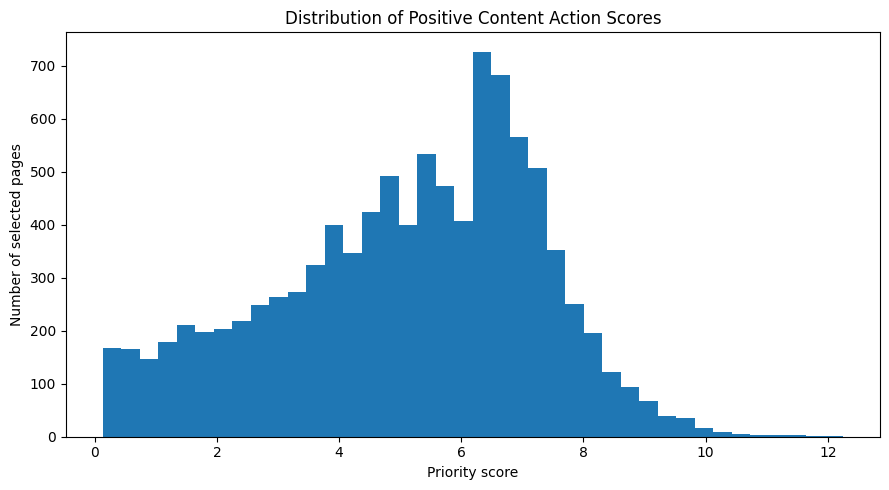

Exports created successfully:
Queue CSV:    /content/flyrank-internship-ml/work/outputs/content_action_queue.csv
Metrics JSON: /content/flyrank-internship-ml/work/outputs/action_playbook_metrics.json
Figure PNG:   /content/flyrank-internship-ml/work/figures/content_action_score_distribution.png

Git tracking reminder:
- Keep content_action_queue.csv untracked.
- Commit action_playbook_metrics.json.
- Commit content_action_score_distribution.png.

Aggregate metrics:


,metric,value
0,artifact,content_action_playbook
1,method,transparent_rule_based_baseline
2,input_rows,30000
3,pages_ranked,30000
4,pages_selected,9759
5,pages_not_selected,20241
6,selected_share_pct,32.53
7,interpretation,Decision-support ranking only; not a predictio...



All export checks passed.


In [6]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Section 5: Export the queue, metrics JSON, and reusable figure

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Verify the required objects exist
if "queue" not in globals() or "df" not in globals():
    raise NameError(
        "Run the Section 1 code cell first to create `queue` and `df`."
    )

# Create output directories
outputs_dir = repo_root / "work" / "outputs"
figures_dir = repo_root / "work" / "figures"

outputs_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Export the ranked queue locally.
# The repository's .gitignore should keep this page-level CSV untracked.
queue_path = outputs_dir / "content_action_queue.csv"
queue.to_csv(queue_path, index=False)

# 2. Calculate aggregate metrics for reproducibility
selected_mask = queue["priority_score"].gt(0)
selected_queue = queue.loc[selected_mask]

reason_code_counts = {
    str(key): int(value)
    for key, value in queue["reason_code"].value_counts().items()
}

metrics = {
    "artifact": "content_action_playbook",
    "method": "transparent_rule_based_baseline",
    "input_rows": int(len(df)),
    "pages_ranked": int(len(queue)),
    "pages_selected": int(selected_mask.sum()),
    "pages_not_selected": int((~selected_mask).sum()),
    "selected_share_pct": round(
        100 * selected_mask.mean(), 2
    ) if len(queue) else 0.0,
    "reason_code_counts": reason_code_counts,
    "selection_rule": {
        "minimum_impressions_90d": 500,
        "average_position_min_exclusive": 0,
        "average_position_max_inclusive": 20,
        "ctr_threshold_pct": 0.5,
        "score_formula": (
            "log1p(impressions_90d) * "
            "max(0, 0.5 - ctr) / 0.5 * visibility_gate"
        ),
    },
    "selected_score_summary": {
        "median": round(
            float(selected_queue["priority_score"].median()), 6
        ) if not selected_queue.empty else None,
        "minimum": round(
            float(selected_queue["priority_score"].min()), 6
        ) if not selected_queue.empty else None,
        "maximum": round(
            float(selected_queue["priority_score"].max()), 6
        ) if not selected_queue.empty else None,
    },
    "interpretation": (
        "Decision-support ranking only; not a prediction of future "
        "performance or a guarantee of business impact."
    ),
}

metrics_path = outputs_dir / "action_playbook_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2, ensure_ascii=False)

# 3. Save a figure showing the positive priority-score distribution
figure_path = figures_dir / "content_action_score_distribution.png"

positive_scores = queue.loc[
    queue["priority_score"] > 0, "priority_score"
]

plt.figure(figsize=(9, 5))

if not positive_scores.empty:
    plt.hist(positive_scores, bins=40)
    plt.xlabel("Priority score")
    plt.ylabel("Number of selected pages")
    plt.title("Distribution of Positive Content Action Scores")
else:
    plt.text(
        0.5, 0.5,
        "No pages passed the selection rule",
        ha="center", va="center",
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# 4. Verify the exports
with open(metrics_path, "r", encoding="utf-8") as file:
    saved_metrics = json.load(file)

assert queue_path.exists() and queue_path.stat().st_size > 0
assert metrics_path.exists() and saved_metrics["pages_ranked"] == len(queue)
assert figure_path.exists() and figure_path.stat().st_size > 0
assert (
    saved_metrics["pages_selected"]
    + saved_metrics["pages_not_selected"]
    == saved_metrics["pages_ranked"]
)

print("Exports created successfully:")
print(f"Queue CSV:    {queue_path}")
print(f"Metrics JSON: {metrics_path}")
print(f"Figure PNG:   {figure_path}")

print("\nGit tracking reminder:")
print("- Keep content_action_queue.csv untracked.")
print("- Commit action_playbook_metrics.json.")
print("- Commit content_action_score_distribution.png.")

print("\nAggregate metrics:")
display(pd.DataFrame(
    [{"metric": key, "value": value}
     for key, value in saved_metrics.items()
     if not isinstance(value, (dict, list))]
))

print("\nAll export checks passed.")

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

In [7]:
%cd /content/flyrank-internship-ml

!git status --short
!git check-ignore -v work/outputs/content_action_queue.csv
!git check-ignore work/outputs/action_playbook_metrics.json
!git check-ignore work/figures/content_action_score_distribution.png

/content/flyrank-internship-ml
?? work/figures/
?? work/outputs/
.gitignore:28:work/**/*.csv	work/outputs/content_action_queue.csv


In [8]:
%cd /content/flyrank-internship-ml

!git add work/notebooks/w07_action_playbook.ipynb
!git add work/outputs/action_playbook_metrics.json
!git add work/figures/content_action_score_distribution.png

!git status --short

/content/flyrank-internship-ml
A  work/figures/content_action_score_distribution.png
A  work/outputs/action_playbook_metrics.json


In [9]:
%cd /content/flyrank-internship-ml
!git status
!git ls-files --error-unmatch work/notebooks/w07_action_playbook.ipynb

/content/flyrank-internship-ml
On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   work/figures/content_action_score_distribution.png
	new file:   work/outputs/action_playbook_metrics.json

work/notebooks/w07_action_playbook.ipynb


In [10]:
%cd /content/flyrank-internship-ml
!git add work/notebooks/w07_action_playbook.ipynb
!git status --short

/content/flyrank-internship-ml
A  work/figures/content_action_score_distribution.png
A  work/outputs/action_playbook_metrics.json


In [11]:
%cd /content/flyrank-internship-ml
!ls -l work/notebooks/w07_action_playbook.ipynb
!git status --short --untracked-files=all
!git check-ignore -v work/notebooks/w07_action_playbook.ipynb

/content/flyrank-internship-ml
-rw-r--r-- 1 root root 3648 Oct 21 11:30 work/notebooks/w07_action_playbook.ipynb
A  work/figures/content_action_score_distribution.png
A  work/outputs/action_playbook_metrics.json


In [12]:
%cd /content/flyrank-internship-ml

!git ls-files --stage work/notebooks/w07_action_playbook.ipynb
!git diff -- work/notebooks/w07_action_playbook.ipynb
!git diff --cached -- work/notebooks/w07_action_playbook.ipynb

/content/flyrank-internship-ml
100644 6477367facb84a409868028a3507ff96381d4f2f 0	work/notebooks/w07_action_playbook.ipynb


In [13]:
%cd /content/flyrank-internship-ml

!git status --short
!git diff --stat -- work/notebooks/w07_action_playbook.ipynb
!git diff --cached --stat -- work/notebooks/w07_action_playbook.ipynb

/content/flyrank-internship-ml
A  work/figures/content_action_score_distribution.png
A  work/outputs/action_playbook_metrics.json


In [14]:
%cd /content/flyrank-internship-ml

!stat work/notebooks/w07_action_playbook.ipynb
!git log -1 --format="Last commit: %h %s" -- work/notebooks/w07_action_playbook.ipynb

/content/flyrank-internship-ml
  File: work/notebooks/w07_action_playbook.ipynb
  Size: 3648      	Blocks: 8          IO Block: 4096   regular file
Device: 0,52	Inode: 6035079     Links: 1
Access: (0644/-rw-r--r--)  Uid: (    0/    root)   Gid: (    0/    root)
Access: 2026-10-21 11:40:17.479352579 +0000
Modify: 2026-10-21 11:30:47.073042106 +0000
Change: 2026-10-21 11:30:47.073042106 +0000
 Birth: 2026-10-21 11:30:47.073042106 +0000
Last commit: eb3fc66 Point Colab badges at this copy [skip ci]
